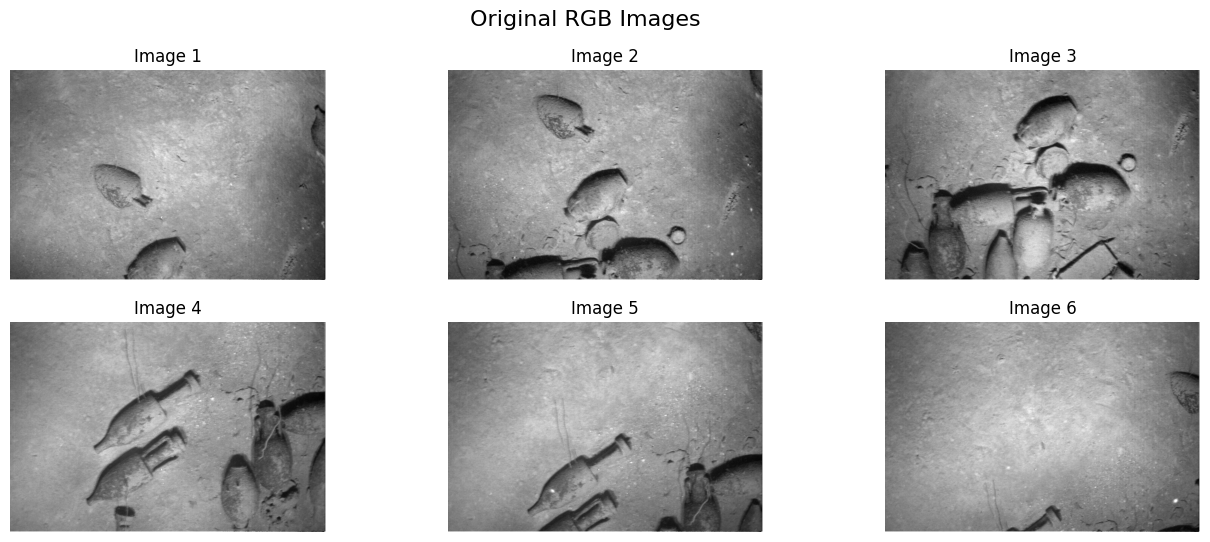

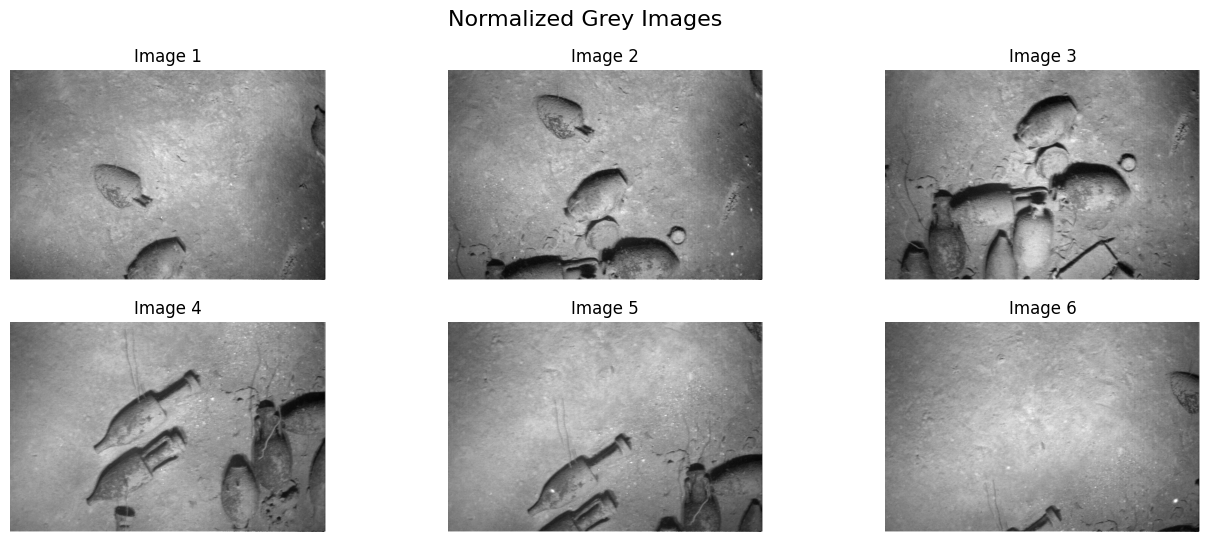

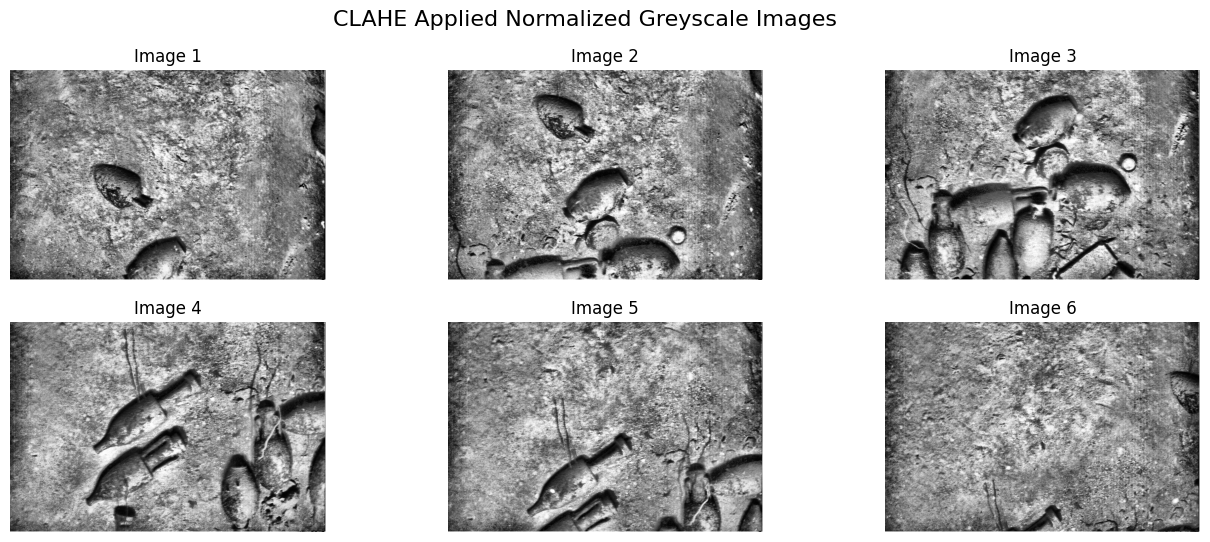

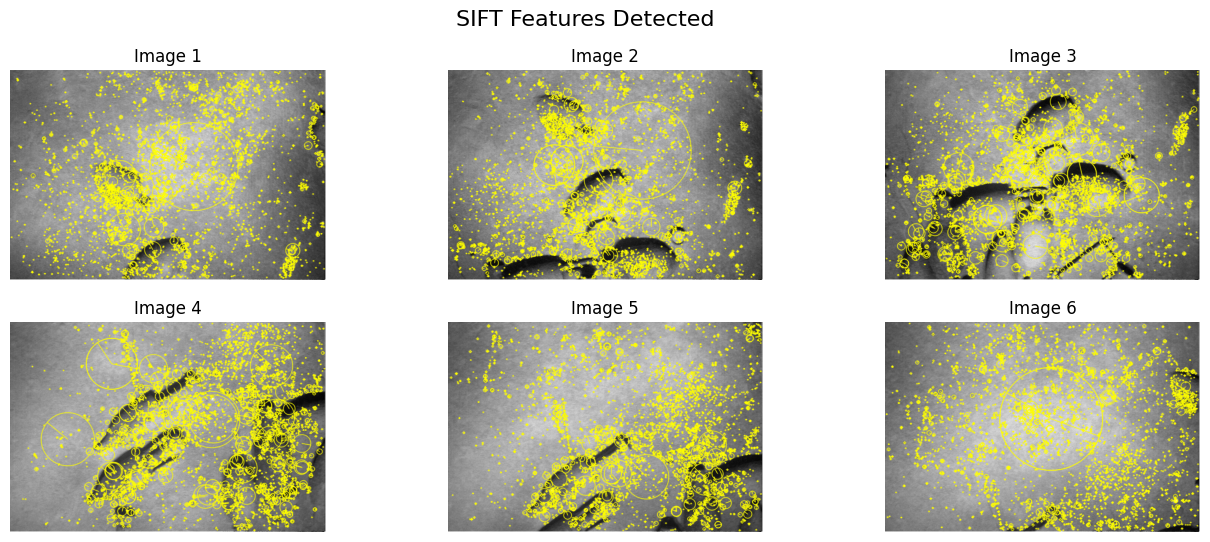

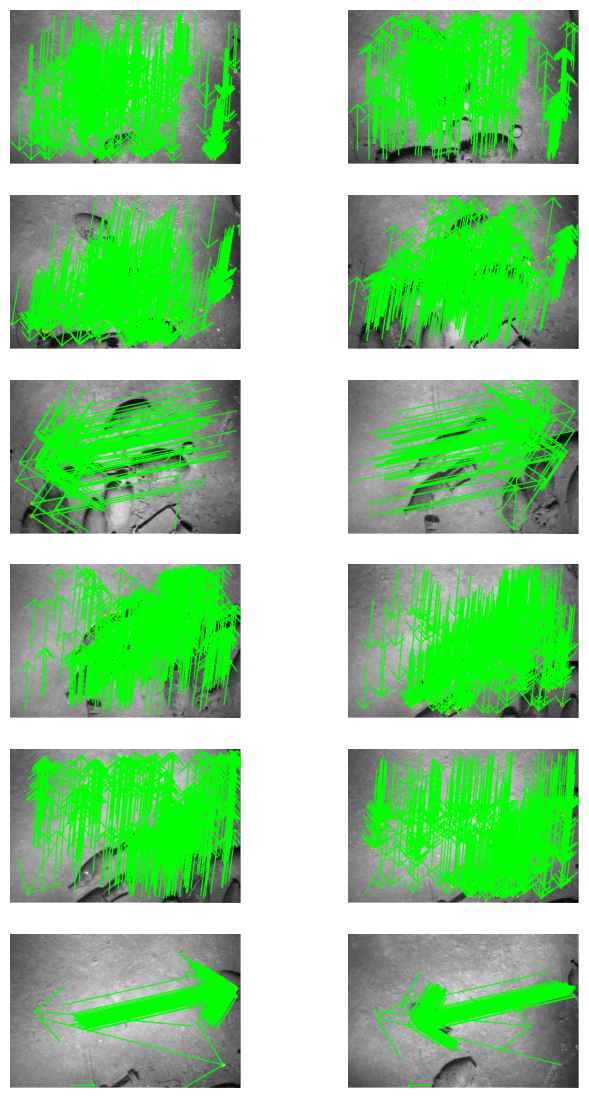

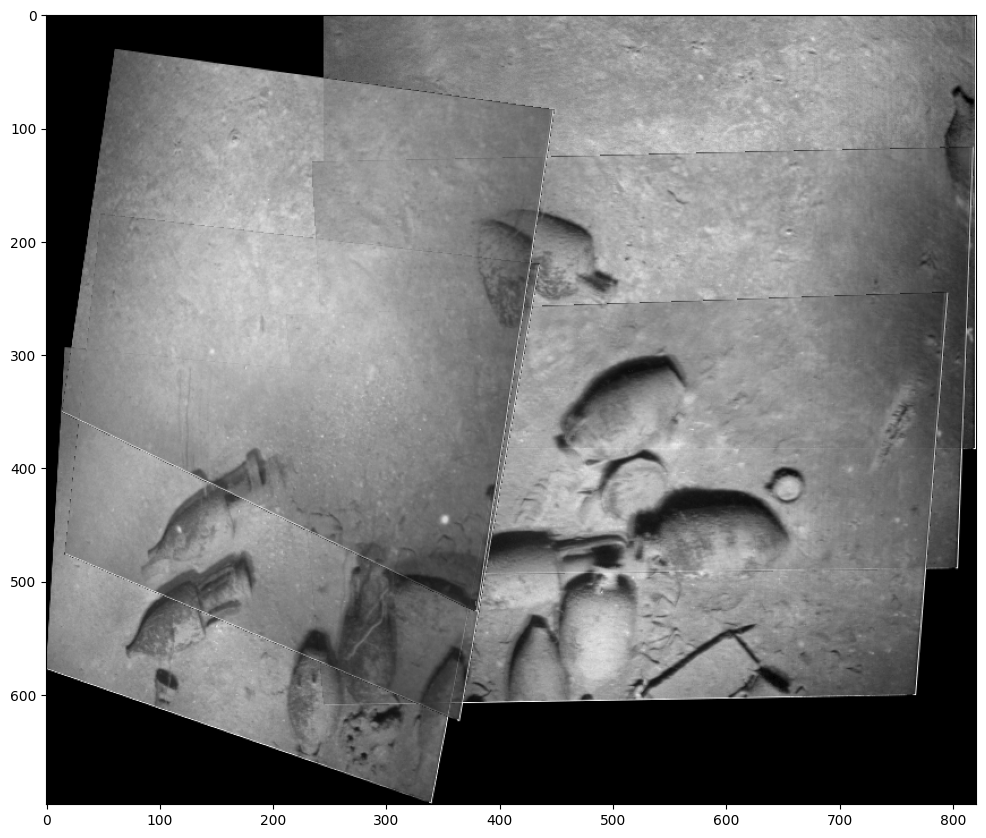

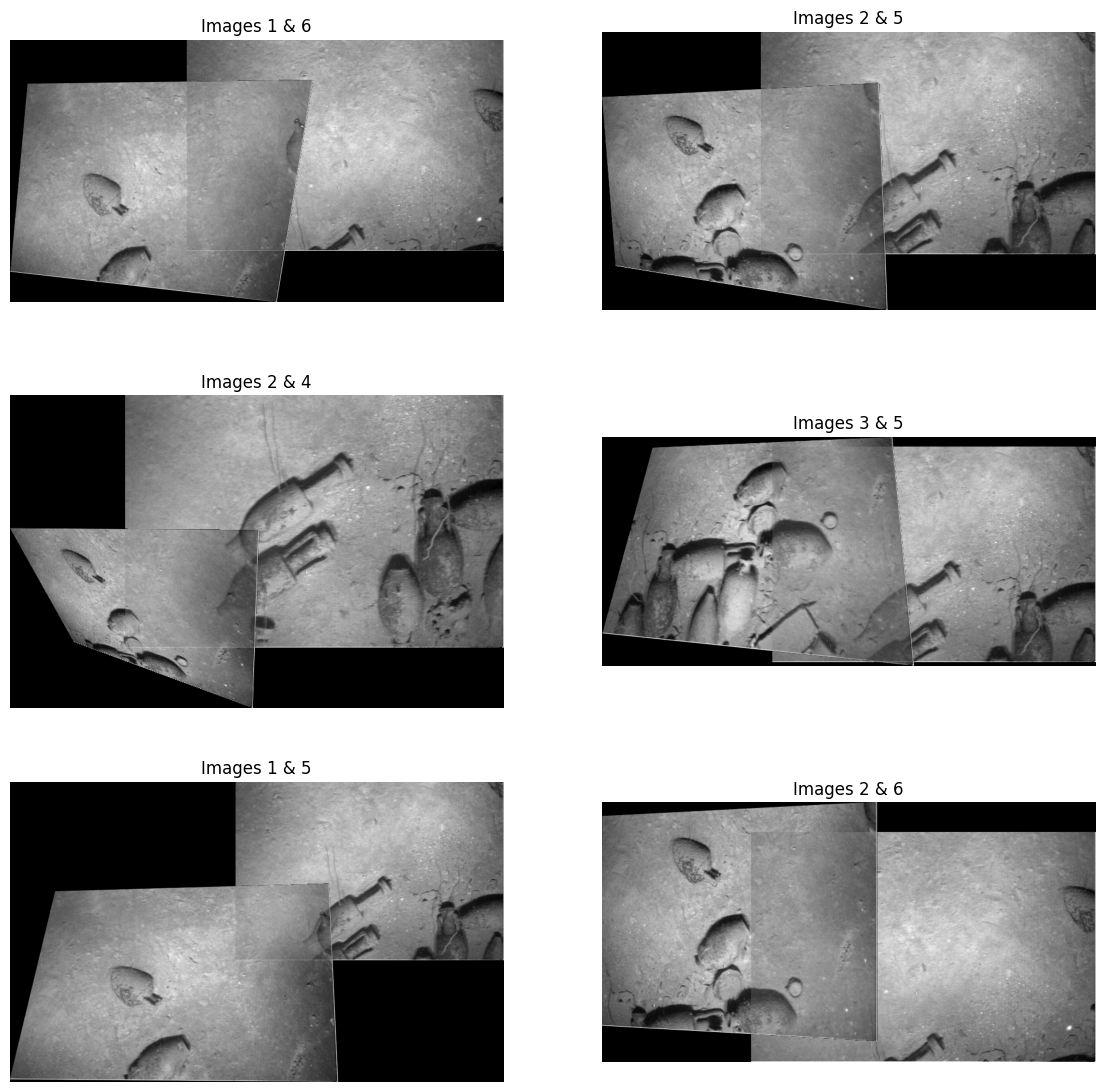

In [1]:
import matplotlib.pyplot as plt
import glob
import os
from itertools import combinations
import cv2
import numpy as np

# LOAD IMAGES INTO A LIST
def load_images(images_folder_path):
    
    images = []
    images_paths_list = sorted(filter(os.path.isfile, glob.glob(images_folder_path + '*')))

    for image_path in images_paths_list:
        images.append(cv2.imread(image_path))

    return images

# CONVERT LIST OF COLOR IMAGES INTO LIST OF GRAYSCALE IMAGES
def convert_to_grayscale(images):
    
    gray_images = [cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) for image in images]

    return gray_images


# NORMALIZE A LIST OF IMAGES. REMEMBER THAT NORMALIZATION MUST OCCUR IN GRAYSCALE ONLY. CAN DO COLOR -> GRAYSCALE & NORMALIZE & GRAYSCALE -> COLOR
def normalize_images(gray_images):
    
    normalized_gray_images = []
    
    # Min-Max Normalization to range [0, 255]
    for image in gray_images:
        
        normalized_gray_image = cv2.normalize(image, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)
        normalized_gray_images.append(normalized_gray_image)

    return normalized_gray_images

# APPLY CLAHE HISTOGRAM EQUALIZATION TO A LIST OF IMAGES. IMAGES IN THE IMAGES LIST CAN BE JUST GRAY IMAGES OR CAN BE NORMALIZED GRAY IMAGES
def apply_clahe(images_list):

        clahe = cv2.createCLAHE(clipLimit=5.0, tileGridSize=(8, 8))       
        clahe_gray_images = [clahe.apply(image) for image in images_list]

        # METHODS TO TEST - 
        # Test 1 - Convert to GREY, apply CLAHE -> USING THIS METHOD NOW
        # Test 2 - Convert to GREY, apply CLAHE and then back to BGR 
        # Test 3 - Convert to LAB, apply CLAHE and then back to BGR

        return clahe_gray_images

# DISPLAY IMAGES USING MATPLOTLIB
def display_images(images, title, ncols=3):

    nrows = len(images) // ncols + (len(images) % ncols > 0)
    fig, axs = plt.subplots(nrows, ncols, figsize=(16, 6))

    fig.suptitle(title, fontsize=16)

    for i in range(len(images)):
        row = i // ncols
        col = i % ncols
        axs[row, col].imshow(images[i], cmap='gray')
        axs[row, col].set_title(f"Image {i + 1}")

    for ax in axs.flat:
        ax.axis('off')

    plt.show()

# DETECT SIFT FEATURES ON GRAY IMAGES OR NORMALIZED GRAY IMAGES
# RETURNS:
# (A) KEYPOINTS LIST: CONTAINS SPATIAL LOCATION FOR DETECTED KEYPOINTS ON EACH IMAGE, LENTH = NUMBER OF IMAGES
# (B) DESCRIPTORS LIST: CONTAINS DESCRIPTORS FOR EACH OF THOSE DETECTED KEYPOINTS, LENGTH = NUMBER OF IMAGES
# (C) OUT_IMAGES: IMAGES WITH DETECTED FEATURES
def detect_features(normalized_gray_images):
    sift = cv2.SIFT_create(nfeatures=4000, nOctaveLayers=12, contrastThreshold=0.025, sigma=1.5)
    kp_list = []
    des_list = []
    out_images = []
    for image in normalized_gray_images:
        kp, des = sift.detectAndCompute(image, None)
        out_image = cv2.drawKeypoints(image, kp, image, color=[255, 255, 0], flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
        kp_list.append(np.array(kp))
        des_list.append(np.array(des))
        out_images.append(out_image)

    return kp_list, des_list, out_images



############################
# LOOPS OVER THE DESCRIPTORS LIST, TAKING TWO SETS OF DESCRIPTORS AT A TIME, AND FINDS MATCHES BETWEEN THESE DESCRIPTORS USING KNN METHOD OF BFMATCHER
# THEN FILTERS THOSE MATCHES USING LOWE RATIO
def match_and_filter(matcher, des1, des2, threshold=0.90, dist_mask_12=None, draw_plot_dist=False):
        
        # First match 2 against 1
        if dist_mask_12 is None:
            dist_mask_21 = None
        else:
            dist_mask_21 = dist_mask_12.T
        matches_knn = matcher.knnMatch(des2, des1, k=2, mask=dist_mask_21)
        all_ds = [m[0].distance for m in matches_knn if len(m) > 0]

        matches = []

        # RIN LOES FILTER AND FILTER WITH DIFFERENCE HIGHER THAN THRESHOLD
        # STILL LEAVES MULTIPLE MATCHES INTO 1 (TRAIN DESCRIPTORS)
        # CREATE A MASK OF SIZE DES1 X DES2 FOR PERMISSIBLE MATCHES

        mask = np.zeros((des1.shape[0], des2.shape[0]), dtype='uint8')
        for match in matches_knn:
            if len(match) == 1 or (len(match) > 1 and match[0].distance < threshold * match[1].distance):

                matches.append(match[0])
                mask[match[0].trainIdx, match[0].queryIdx] = 1

        if draw_plot_dist:
            fig, axes = plt.subplots(1, 1, num=3)
            filt_ds = [m.distance for m in matches]
            axes.plot(sorted(all_ds), '.', label='All Matches')
            axes.plot(sorted(filt_ds), '.', label='Filtered Matches')
            axes.set_xlabel('Number')
            axes.set_ylabel('Distance')
            axes.legend()
            plt.pause(.1)
        
        # REMOVALL OF DUPLICATES BY RUNNING MATCHES USING THE MAST BUT FROM 1 TO 2
        # THIS IS SAME AS RUNNING CROSS-MATCH AFTER LOWE RATIO TEST
        matches_cross = matcher.match(des1, des2, mask=mask)

        return matches_cross

##########################
# USES THE FUNCTION ABOVE BETWEEN ALL PAIRS OF DESCRIPTORS AND RETURNS KEYPOINTS CORRESPONDING TO MATCHING DESCRIPTORS
def get_matches(kp_list, des_list, only_image_pair=False):

    matcher = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)
    matches = []

    # KP_MATCH: LIST OF TUPLES WITH KP_MATCH[I] = (KP0_MATCH, KP1_MATCH)
    kp_match = []
    if only_image_pair:
        matches.append(match_and_filter(matcher, des_list[0], des_list[1], threshold=0.90))
        kp0_match_pts = np.array([kp_list[0][mat.queryIdx].pt for mat in matches[0]])
        kp1_match_pts = np.array([kp_list[1][mat.trainIdx].pt for mat in matches[0]])
        kp_match.append((kp0_match_pts, kp1_match_pts))
    else:
        # SEQUENTIAL MATCHING
        for i in range(6):
            if i < 5:
                matches.append(match_and_filter(matcher, des_list[i], des_list[i + 1], threshold=0.90))
                kp0_match_pts = np.array([kp_list[i][mat.queryIdx].pt for mat in matches[i]])
                kp1_match_pts = np.array([kp_list[i + 1][mat.trainIdx].pt for mat in matches[i]])
            else:
                # IF i IS AT THE LAST IMAGE INDEX, MATCH THE LAST IMAGE WITH THE FIRST IMAGE (6 TO 1)
                matches.append(match_and_filter(matcher, des_list[i], des_list[0], threshold=0.90))
                kp0_match_pts = np.array([kp_list[i][mat.queryIdx].pt for mat in matches[i]])
                kp1_match_pts = np.array([kp_list[0][mat.trainIdx].pt for mat in matches[i]])

            kp_match.append((kp0_match_pts, kp1_match_pts))
    return matches, kp_match


###################
# GENERATES FUNDAMENTAL MATRIX FROM MATCHING SETS OF KEYPOINTS AFTER REMOVING THE OUTLIERS USING RANSAC AND REPROJECTION ERROR
def get_inliers(kp_list, des_list, matches, kp_match):

    mask_e = []
    kp_match_inliers = []
    i = 0
    for k_match in kp_match:
        F, maskMatch = cv2.findFundamentalMat(k_match[0], k_match[1],
                                                method=cv2.FM_RANSAC,
                                                ransacReprojThreshold=1.0,
                                                confidence=0.9999)
        mask_e.append(maskMatch)

        kp0_match_inliers = [kp_list[i][mat.queryIdx] for mat, msk in zip(matches[i], mask_e[i]) if msk]
        if i < 5:
            kp1_match_inliers = [kp_list[i + 1][mat.trainIdx] for mat, msk in zip(matches[i], mask_e[i]) if msk]
        else:
            kp1_match_inliers = [kp_list[0][mat.trainIdx] for mat, msk in zip(matches[i], mask_e[i]) if msk]

        kp_match_inliers.append((kp0_match_inliers, kp1_match_inliers))
        i += 1

    return kp_match_inliers, mask_e

###################
def draw_arrows(vis_orig, points1, points2, color=(0, 255, 0), thick=2, tip_length=0.25):
    if len(vis_orig.shape) == 2:
        vis = cv2.cvtColor(vis_orig, cv2.COLOR_GRAY2RGB)
    else:
        vis = vis_orig
    for p1, p2 in zip(points1, points2):
        cv2.arrowedLine(vis, (int(p1[0]), int(p1[1])), (int(p2[0]), int(p2[1])),
                        color=color, thickness=thick, tipLength=tip_length)
    return vis


####################
# TAKES 2 IMAGES, SET OF ALL (OUTLIERS AND INLIERS) KEYPOINTS, MASK OF VALID KEYPOINTS AND PLOTS INLIERS IN GREEN AND OUTLIERS IN RED 
def draw_feature_tracks(img_left, kp1, img_right, kp2, matches, mask, display_invalid=False, color=(0, 255, 0), thick=2):

    bool_mask = mask.astype(bool)
    valid_right_matches = np.array([kp2[mat.trainIdx].pt for is_match, mat in zip(bool_mask, matches) if is_match])
    valid_left_matches = np.array([kp1[mat.queryIdx].pt for is_match, mat in zip(bool_mask, matches) if is_match])

    img_right_out = draw_arrows(img_right, valid_left_matches, valid_right_matches, thick=thick)
    img_left_out = draw_arrows(img_left, valid_right_matches, valid_left_matches, thick=thick)

    return img_left_out, img_right_out

##############################
def draw_inliers(gray_imgs, matches, kp_match_inliers, mask_e):
    i = 0
    match_imgs = []
    for kp_inlier in kp_match_inliers:
        gr0_inliers = cv2.drawKeypoints(gray_imgs[i], kp_inlier[0], gray_imgs[i], color=[255, 255, 0],
                                        flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

        if i < 5:
            gr1_inliers = cv2.drawKeypoints(gray_imgs[i + 1], kp_inlier[1], gray_imgs[i], color=[255, 255, 0],
                                            flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

            matches_img_left, matches_img_right = draw_feature_tracks(
                gr0_inliers, kp_list[i], gr1_inliers, kp_list[i + 1], matches[i],
                mask_e[i], display_invalid=True, color=(0, 255, 0),
                thick=2)
        else:
            gr1_inliers = cv2.drawKeypoints(gray_imgs[0], kp_inlier[1], gray_imgs[i], color=[255, 255, 0],
                                            flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

            matches_img_left, matches_img_right = draw_feature_tracks(
                gr0_inliers, kp_list[i], gr1_inliers, kp_list[0], matches[i],
                mask_e[i], display_invalid=True, color=(0, 255, 0),
                thick=2)

        match_imgs.append((matches_img_left, matches_img_right))
        i += 1

    return match_imgs

###########################
# TAKES MATCHING (INLIERS) KEYPOINTS 
def homography_calculation(kp_match_inliers, inliers=True):
    h = []
    pts_left_src = []
    pts_right_dst = []
    mask = []
    
    if inliers:
        for kp_match in kp_match_inliers:
            pts_left_src.append(np.float32([kp_match[0][i].pt for i in range(len(kp_match[0]))]))
            pts_right_dst.append(np.float32([kp_match[1][i].pt for i in range(len(kp_match[1]))]))
    else:
        for kp_match in kp_match_inliers:
            pts_left_src.append(np.float32([kp_match[0][i] for i in range(len(kp_match[0]))]))
            pts_right_dst.append(np.float32([kp_match[1][i] for i in range(len(kp_match[1]))]))
    
    for i in range(len(pts_left_src)):
        if inliers:
            h_img, mask_img = cv2.findHomography(pts_right_dst[i], pts_left_src[i])
        else:
            h_img, mask_img = cv2.findHomography(pts_right_dst[i], pts_left_src[i], cv2.RANSAC, 1.0)
        h.append(h_img)
        mask.append(mask_img)
    
    return h, mask

# EXTRACTS FOREGROUND FROM BOTH IMAGES ->
# 1. FOR BOTH IMAGES, CREATES MASK CONTAINING ONLY THE NON-BLACK PIXELS (FOREGROUND)
# 2. CREATES A SINGLE FOREGROUND (NON-BLACK) MASK WITH NON-BLACK PIXELS FROM "EITHER" IMAGE 1 OR IMAGE 2
# 3. FOR BOTH IMAGES, CREATE A NEW FOREGROUND IMAGE (FOREGROUND IMAGE 1 AND FOREGROUND IMAGE 2) USING THE COMBINED FOREGROUND MASK (FROM STEP 2)
# 4. COMBINE THE TWO FOREGROUND IMAGES USING WEIGHTED AVERGAING (70% FOR 1ST FOREGROUND IMAGE AND 30% FOR 2ND FOREGROUND IMAGE) TO FORM A SINGLE FOREGORUND IMAGE 
# EXTRACTS BACKGROUND FROM BOTH IMAGES ->
# 1. CREATE A SINGLE BACKGROUND (BLACK OR NEAR BLACK) MASK DIRECTLY BY INVERTING THE SINGLE FOREGROUND IMAGE OBTAINED IN STEP 2 OF 1ST ROUTINE. THIS WILL REPRESENT THE PIXELS WHERE EITHER IMAGE 1 OR IMAGE 2 IS BLACK.
# 2. FOR BOTH IMAGES, CREATE A NEW MASK THAT WILL REPRESENT THE PIXELS WHERE IMAGE 1 IS NON-BLACK 
def alpha_blending(img1, img2):
    
    # CREATE MASK REPRESENTING BLACK (OR NEAR BLACK) PIXELS IN ORIGINAL IMAGES  (FOREGROUND IN EACH IMAGE)
    mask1 = cv2.inRange(img1, np.array([0, 0, 0]), np.array([5, 5, 5]))
    mask2 = cv2.inRange(img2, np.array([0, 0, 0]), np.array([5, 5, 5]))

    # INVERT THE MASK TO REPRESENT NON-BLACK PIXELS IN ORIGINAL IMAGES  (BACKGROUND IN EACH IMAGE)
    mask1 = cv2.bitwise_not(mask1)
    mask2 = cv2.bitwise_not(mask2)

    # COMBINE THE NON-BLACK MASKS TO REPRESENT PIXELS THAT ARE NON-BLACK IN "BOTH" IMAGE 1 AND IMAGE 2  (BACKGROUND IN BOTH IMAGE 1 AND IMAGE 2)
    mask = cv2.bitwise_and(mask1, mask2)

    # INVERT THE COMBINED NON-BLACK MASK TO REPRESENT PIXELS THAT ARE BLACK IN "EITHER" IMAGE 1 OR IMAGE 2   (FOREGROUND IN EITHER IMAGE 1 OR IMAGE 2)
    mask_inv = cv2.bitwise_not(mask)

    # EXTRACT FOREGROUND (OR BACKGROUND ???) PIXELS FROM IMAGE 1 USING THE COMBINED NON-BLACK MASK     ??????????????????
    img1_fg = cv2.bitwise_and(img1, img1, mask=mask)
    # EXTRACT FOREGROUND (OR BACKGROUND ???) PIXELS FROM IMAGE 2 USING THE COMBINED NON-BLACK MASK     ??????????????????
    img2_fg = cv2.bitwise_and(img2, img2, mask=mask)

    # COMBINE THE FOREGROUND IMAGES USING WEIGHTED AVERAGING (70% FOR IMAGE 1 AND 30% FOR IMAGE 2)    
    img_fg = cv2.addWeighted(img1_fg, 0.7, img2_fg, 0.3, 0)

    # EXTRACT BACKGROUND PIXELS FROM IMAGE 1 USING THE 
    img1_bg = cv2.bitwise_and(img1, img1, mask=cv2.bitwise_and(mask1, mask_inv))    
    img2_bg = cv2.bitwise_and(img2, img2, mask=cv2.bitwise_and(mask2, mask_inv))

     
    img = cv2.add(img2_bg, img1_bg)
    img = cv2.add(img, img_fg)

    return img

##############################
# WARP IMAGE 2 TO IMAGE 1 USING HOMOGRAPHY MATRIX H
def two_image_warping(img1, img2, H):

    h1, w1 = img1.shape[:2]
    h2, w2 = img2.shape[:2]
    pts1 = np.float32([[[0, 0], [0, h1], [w1, h1], [w1, 0]]]).reshape(-1, 1, 2)
    pts2 = np.float32([[[0, 0], [0, h2], [w2, h2], [w2, 0]]]).reshape(-1, 1, 2)
    pts2_ = cv2.perspectiveTransform(pts2, H)
    pts = np.concatenate((pts1, pts2_), axis=0)
    [xmin, ymin] = np.int32(pts.min(axis=0).ravel() - 0.5)
    [xmax, ymax] = np.int32(pts.max(axis=0).ravel() + 0.5)
    t = [-xmin, -ymin]
    shift = pts2_[0][0]
    Ht = np.asarray([[1, 0, t[0]], 
                     [0, 1, t[1]], 
                     [0, 0, 1]])  # translate
    result = cv2.warpPerspective(img2, Ht.dot(H), (xmax - xmin, ymax - ymin))
    H_t = np.dot(np.eye(3), np.asarray([[1, 0, t[0]], [0, 1, t[1]], [0, 0, 1]]))
    tmp = cv2.warpPerspective(img1, H_t, (xmax - xmin, ymax - ymin))
    output = alpha_blending(result, tmp)
    return output, t


def create_mosaic(normImgs, kp_match):

    h, mask = homography_calculation(kp_match, inliers=False)
    t = [0, 0]
    mosaicImg = None

    for i in range(len(h) - 1):
        h[i][0][2] += t[0]
        h[i][1][2] += t[1]

        if i != 0:
            h[i] = np.dot(h[i], h[i - 1])

        if i == 0:
            mosaicImg, t = two_image_warping(normImgs[i], normImgs[i + 1], h[i])
        elif 0 < i < 5:
            mosaicImg, t = two_image_warping(mosaicImg, normImgs[i + 1], h[i])
        else:
            mosaicImg, t = two_image_warping(mosaicImg, normImgs[0], h[i])
    
    plt.figure(figsize=(12, 12))
    plt.imshow(mosaicImg)

def two_image_registration(images, index1, index2, kp_list, des_list, normImgs):

    gray16 = [images[index1], images[index2]]
    kp16 = [kp_list[index1], kp_list[index2]]
    des16 = [des_list[index1], des_list[index2]]
    matcher = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)
    
    matches, kp_match = get_matches(kp16, des16, only_image_pair=True)
    kp_match_inliers, mask_e = get_inliers(kp16, des16, matches, kp_match)

    h, mask = homography_calculation(kp_match, inliers=False)
    result, t = two_image_warping(normImgs[index2], normImgs[index1], h[0])

    return result


if __name__ == "__main__":
    
    images_folder_path = "6Images/"
    images = load_images(images_folder_path)
    display_images(images, "Original RGB Images", ncols=3)
    
    gray_images = convert_to_grayscale(images)

    normalized_gray_images = normalize_images(gray_images)
    display_images(normalized_gray_images, "Normalized Grey Images", ncols=3)

    clahe_normalized_gray_images = apply_clahe(normalized_gray_images)
    display_images(clahe_normalized_gray_images, "CLAHE Applied Normalized Greyscale Images", ncols=3)

    kp_list, des_list, out_images = detect_features(normalized_gray_images)
    display_images(out_images, "SIFT Features Detected", ncols=3)

    matches, kp_match = get_matches(kp_list, des_list)

    kp_match_inliers, mask_e = get_inliers(kp_list, des_list, matches, kp_match) 

    matchImgs = draw_inliers(normalized_gray_images, matches, kp_match_inliers, mask_e)

    # Display the resulting images
    fig, fig_axes = plt.subplots(6, 2, figsize=(8, 14))
    for i in range(len(fig_axes)):
        for j in range(2):
            fig_axes[i, j].imshow(matchImgs[i][j])
            fig_axes[i, j].axis("off")

    plt.draw()
    plt.show(block=True)

    normalized_images = [cv2.cvtColor(image, cv2.COLOR_GRAY2BGR) for image in normalized_gray_images]
    create_mosaic(normalized_images, kp_match)

    result16 = two_image_registration(gray_images, 0, 5, kp_list, des_list, normalized_images)
    result25 = two_image_registration(gray_images, 1, 4, kp_list, des_list, normalized_images)
    result24 = two_image_registration(gray_images, 1, 3, kp_list, des_list, normalized_images)
    result15 = two_image_registration(gray_images, 0, 4, kp_list, des_list, normalized_images)
    result26 = two_image_registration(gray_images, 1, 5, kp_list, des_list, normalized_images)
    result35 = two_image_registration(gray_images, 2, 4, kp_list, des_list, normalized_images)


    fig, axes = plt.subplots(3, 2, figsize=(14, 14))
    axes[0, 0].imshow(result16)
    axes[0, 0].set_title("Images 1 & 6")
    axes[0, 0].axis("off")

    axes[0, 1].imshow(result25)
    axes[0, 1].set_title("Images 2 & 5")
    axes[0, 1].axis("off")

    axes[1, 0].imshow(result24)
    axes[1, 0].set_title("Images 2 & 4")
    axes[1, 0].axis("off")

    axes[1, 1].imshow(result35)
    axes[1, 1].set_title("Images 3 & 5")
    axes[1, 1].axis("off")

    axes[2, 0].imshow(result15)
    axes[2, 0].set_title("Images 1 & 5")
    axes[2, 0].axis("off")

    axes[2, 1].imshow(result26)
    axes[2, 1].set_title("Images 2 & 6")
    axes[2, 1].axis("off")